# Derin Öğrenme Dersi - Ödev 1: MNIST Veri Seti ile MLP Tabanlı El Yazısı Rakam Tanıma

* **Öğrenci Numarası:** `23120205011`
* **Model Mimarisi:** Multi-Layer Perceptron (MLP) - *CNN kullanılmamıştır.*
* **Kütüphane:** PyTorch

---

### Ödevin Amacı ve Kapsamı
Bu çalışmada, klasik MNIST el yazısı rakam veri kümesi kullanılarak sıfırdan bir Çok Katmanlı Algılayıcı (Multi-Layer Perceptron - MLP) modeli tasarlanmış, eğitilmiş ve optimize edilmiştir.
Çalışma 3 ana etaptan oluşmaktadır:
1. **Temel MLP Modeli (Deney 1):** En az 2 gizli katmanlı (hidden layer), ReLU aktivasyonlu temel bir modelin Train (50.000) ve Validation (10.000) kümeleri üzerinde eğitilmesi, metriklerinin (loss, accuracy, süre) raporlanması ve öğrenme eğrilerinin çıkarılması.
2. **Hiperparametre Karşılaştırması (Deney 2):** Katman genişliği, öğrenme oranı (learning rate), optimizasyon algoritması (Adam vs SGD+Momentum) ve regülarizasyon (Dropout) gibi kritik faktörlerin sistematik kıyaslanması; en iyi modelin **sadece validation performansı** gözetilerek seçilmesi ve test kümesinde (10.000) tek seferlik nihai sınamaya tabi tutulması.
3. **Kendi El Yazısı Değerlendirmesi (Öğrenci Numarası):** Kağıda el yazısıyla yazılan öğrenci numarası (`23120205011`) görüntüsünün işlenmesi, MNIST standartlarına (20x20 kütle merkezi hizalı, 28x28 boyut, siyah zemin-beyaz mürekkep, normalizasyon) dönüştürülmesi ve modelin gerçek dünya el yazısı üzerindeki başarısının / genelleme farkının (*distribution shift / domain gap*) incelenmesi.


In [1]:
import os
import io
import time
import random
import shutil
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image, ImageOps
import scipy.ndimage as ndimage
from sklearn.metrics import confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets

# ============================ GENEL AYARLAR ============================
STUDENT_NO = "23120205011"
SEED       = 42
EPOCHS     = 20
BATCH_SIZE = 128

# MNIST veri seti resmi ortalama ve standart sapma değerleri
MNIST_MEAN = 0.1307
MNIST_STD  = 0.3081

# Çıktı ve veri dizinleri
OUT_DIR    = "results"
DIGITS_DIR = "my_digits"
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(DIGITS_DIR, exist_ok=True)

# Tekrarlanabilirlik (Reproducibility) için Seed Sabitleme
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Kullanılan Hesaplama Cihazı: {device}")
print(f"Hedef Öğrenci Numarası: {STUDENT_NO} (Uzunluk: {len(STUDENT_NO)} hane)")




Kullanılan Hesaplama Cihazı: cpu
Hedef Öğrenci Numarası: 23120205011 (Uzunluk: 11 hane)


## 1. Veri Setinin İndirilmesi, Ön İşlenmesi ve Kümelerin Ayrılması

Hocanın yönergesine göre veriler açıkça üç bağımsız kümeye ayrılmalıdır:
* **Eğitim (Train) Kümesi:** 50.000 örnek (Model ağırlıklarının güncellenmesi için).
* **Doğrulama (Validation) Kümesi:** 10.000 örnek (Hiperparametre seçimi, erken durdurma ve overfitting takibi için).
* **Test Kümesi:** 10.000 örnek (Resmi MNIST test seti; model geliştirme sürecinde **asla** kullanılmaz, sadece final modelin tek seferlik başarısını ölçmek için saklanır).

Görüntüler [0, 1] aralığına çekilip `MNIST_MEAN` ve `MNIST_STD` ile normalize edilir ve MLP'ye uygun şekilde 784 boyutlu vektörlere (`28x28 -> 784`) düzleştirilir.


100%|██████████| 9.91M/9.91M [00:00<00:00, 131MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 34.7MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 125MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.35MB/s]


=== VERİ AYRIMI RAPORU ===
Eğitim (Train) Kümesi     :  50000 örnek (MNIST Train setinden)
Doğrulama (Validation)    :  10000 örnek (MNIST Train setinden, Train ile kesişmez)
Test Kümesi (Nihai Sınama):  10000 örnek (MNIST Test setinden, ayrı tutuluyor)


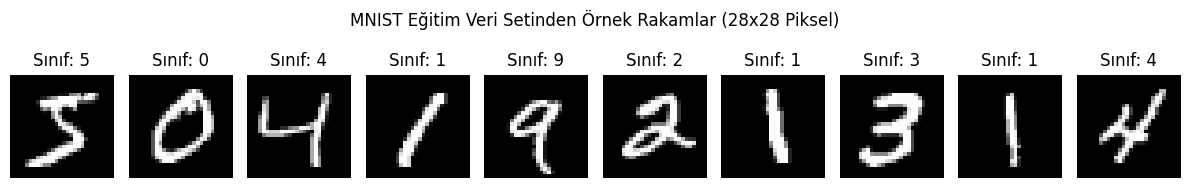

In [2]:
# 1. MNIST Veri Setini İndir
train_full = datasets.MNIST("./data", train=True, download=True)
test_raw   = datasets.MNIST("./data", train=False, download=True)

# 2. Vektörleştirme ve Normalizasyon Fonksiyonu
def prepare_tensors(raw_uint8):
    # uint8 [0, 255] -> float [0.0, 1.0] -> normalize
    x = raw_uint8.float() / 255.0
    x = (x - MNIST_MEAN) / MNIST_STD
    return x.view(len(x), -1)  # 28x28 boyutundan 784 düz vektöre dönüştür

# 3. Train ve Validation Ayrımı (50.000 / 10.000)
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(train_full), generator=g)
train_indices = perm[:50000]
val_indices   = perm[50000:]

X_train = prepare_tensors(train_full.data[train_indices]).to(device)
y_train = train_full.targets[train_indices].to(device)

X_val   = prepare_tensors(train_full.data[val_indices]).to(device)
y_val   = train_full.targets[val_indices].to(device)

# Test verisi model geliştirme süresince ayrı tutulur
_TEST_DATA = (test_raw.data, test_raw.targets)

print("=== VERİ AYRIMI RAPORU ===")
print(f"Eğitim (Train) Kümesi     : {len(X_train):>6} örnek (MNIST Train setinden)")
print(f"Doğrulama (Validation)    : {len(X_val):>6} örnek (MNIST Train setinden, Train ile kesişmez)")
print(f"Test Kümesi (Nihai Sınama): {len(_TEST_DATA[0]):>6} örnek (MNIST Test setinden, ayrı tutuluyor)")

# Kümeler arası kesişim olmadığını doğrula
assert len(set(train_indices.tolist()) & set(val_indices.tolist())) == 0, "Hata: Train ve Validation kümeleri kesişiyor!"

# Örnek birkaç MNIST rakamını görselleştir
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for idx in range(10):
    sample_img = train_full.data[idx].numpy()
    axes[idx].imshow(sample_img, cmap="gray")
    axes[idx].set_title(f"Sınıf: {train_full.targets[idx].item()}")
    axes[idx].axis("off")
plt.suptitle("MNIST Eğitim Veri Setinden Örnek Rakamlar (28x28 Piksel)", y=1.05)
plt.tight_layout()
plt.show()




## 2. MLP Model Mimarisi ve Eğitim / Değerlendirme Altyapısı

Modelimiz şu kurallara göre tasarlanmıştır:
* **Giriş:** 784 nöron (düzleştirilmiş $28 \times 28$ gri seviye görüntü).
* **Gizli Katmanlar (Hidden Layers):** En az 2 gizli katman.
* **Aktivasyon:** ReLU ($f(x) = \max(0, x)$).
* **Çıkış:** 10 nöron (0-9 sınıfları için logit değerleri).
* **Kayıp Fonksiyonu:** Cross-Entropy Loss (Softmax ve Negative Log-Likelihood birleşimi).


In [3]:
class MLP(nn.Module):
    """
    Esnek Çok Katmanlı Algılayıcı (MLP) Mimarisi.
    CNN kullanılmamıştır; tamamen tam bağlantılı (Linear) katmanlardan oluşur.
    """
    def __init__(self, hidden_layers=(256, 128), dropout=0.0):
        super().__init__()
        layers = []
        in_dim = 784

        for h_dim in hidden_layers:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.ReLU())
            if dropout > 0.0:
                layers.append(nn.Dropout(dropout))
            in_dim = h_dim

        layers.append(nn.Linear(in_dim, 10))  # 10 sınıf çıktısı
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

@torch.no_grad()
def evaluate_model(model, X, y, batch_size=10000):
    """Modelin eval modunda kayıp (loss) ve doğruluk (accuracy) değerlerini hesaplar."""
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = len(X)

    for i in range(0, total_samples, batch_size):
        xb = X[i:i + batch_size]
        yb = y[i:i + batch_size]
        logits = model(xb)
        loss = F.cross_entropy(logits, yb, reduction="sum")
        total_loss += loss.item()
        total_correct += (logits.argmax(dim=1) == yb).sum().item()

    return total_loss / total_samples, total_correct / total_samples

def train_experiment(name, cfg, verbose=True):
    """Belirtilen konfigürasyon ile modeli sıfırdan eğitir ve metrikleri kaydeder."""
    set_seed(SEED)
    model = MLP(hidden_layers=cfg["hidden"], dropout=cfg.get("dropout", 0.0)).to(device)

    # Optimizer Seçimi
    if cfg["opt"] == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=cfg.get("momentum", 0.9))

    criterion = nn.CrossEntropyLoss()

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_record = {"val_loss": float("inf"), "epoch": 0, "state_dict": None}

    num_train = len(X_train)
    if device.type == "cuda":
        torch.cuda.synchronize()
    start_time = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        permutation = torch.randperm(num_train, device=device)

        for i in range(0, num_train, BATCH_SIZE):
            batch_idx = permutation[i:i + BATCH_SIZE]
            xb, yb = X_train[batch_idx], y_train[batch_idx]

            optimizer.zero_grad(set_to_none=True)
            outputs = model(xb)
            loss = criterion(outputs, yb)
            loss.backward()
            optimizer.step()

        # Her epoch sonunda eşit koşulda (eval modu) ölçüm
        tr_loss, tr_acc = evaluate_model(model, X_train, y_train)
        va_loss, va_acc = evaluate_model(model, X_val, y_val)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)

        if va_loss < best_record["val_loss"]:
            best_record["val_loss"] = va_loss
            best_record["epoch"] = epoch
            best_record["state_dict"] = {k: v.detach().clone() for k, v in model.state_dict().items()}

        if verbose:
            print(f"Epoch {epoch:>2}/{EPOCHS} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {va_loss:.4f} Acc: {va_acc:.4f}")

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed_time = time.time() - start_time

    best_ep_idx = best_record["epoch"] - 1
    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    return {
        "name": name,
        "cfg": cfg,
        "history": history,
        "best_state": best_record["state_dict"],
        "best_epoch": best_record["epoch"],
        "best_val_loss": history["val_loss"][best_ep_idx],
        "best_val_acc": history["val_acc"][best_ep_idx],
        "best_train_loss": history["train_loss"][best_ep_idx],
        "best_train_acc": history["train_acc"][best_ep_idx],
        "time": elapsed_time,
        "params": total_params
    }

def plot_training_curves(history, title, save_path):
    """Eğitim ve doğrulama eğrilerini (Loss & Accuracy) yan yana çizer."""
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Loss Grafiği
    axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", color="#1f77b4", lw=2)
    axes[0].plot(epochs_range, history["val_loss"], label="Validation Loss", color="#ff7f0e", lw=2, linestyle="--")
    axes[0].set_title(f"{title} - Kayıp (Loss) Eğrisi", fontsize=12)
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross Entropy Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Accuracy Grafiği
    axes[1].plot(epochs_range, history["train_acc"], label="Train Accuracy", color="#2ca02c", lw=2)
    axes[1].plot(epochs_range, history["val_acc"], label="Validation Accuracy", color="#d62728", lw=2, linestyle="--")
    axes[1].set_title(f"{title} - Başarım (Accuracy) Eğrisi", fontsize=12)
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Doğruluk Oranı")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()




## 3. Deney 1 – Temel MLP Modeli

* **Mimari:** $784 \rightarrow 256 \rightarrow 128 \rightarrow 10$ (2 Gizli Katman, ReLU Aktivasyon)
* **Optimizer:** Adam (Öğrenme Oranı $lr = 0.001$)
* **Kayıp Fonksiyonu:** Cross-Entropy Loss
* **Batch Boyutu:** 128 | **Epoch Sayısı:** 20 | **Rastgelelik Tohumu (Seed):** 42


=== DENEY 1: TEMEL MLP EĞİTİMİ BAŞLIYOR ===
Yapılandırma: {'hidden': (256, 128), 'opt': 'adam', 'lr': 0.001, 'dropout': 0.0}
Epoch  1/20 | Train Loss: 0.1372 Acc: 0.9580 | Val Loss: 0.1697 Acc: 0.9477
Epoch  2/20 | Train Loss: 0.0831 Acc: 0.9740 | Val Loss: 0.1205 Acc: 0.9635
Epoch  3/20 | Train Loss: 0.0546 Acc: 0.9829 | Val Loss: 0.1009 Acc: 0.9703
Epoch  4/20 | Train Loss: 0.0441 Acc: 0.9855 | Val Loss: 0.0994 Acc: 0.9713
Epoch  5/20 | Train Loss: 0.0257 Acc: 0.9921 | Val Loss: 0.0889 Acc: 0.9752
Epoch  6/20 | Train Loss: 0.0287 Acc: 0.9908 | Val Loss: 0.1007 Acc: 0.9707
Epoch  7/20 | Train Loss: 0.0193 Acc: 0.9936 | Val Loss: 0.0857 Acc: 0.9764
Epoch  8/20 | Train Loss: 0.0204 Acc: 0.9931 | Val Loss: 0.0962 Acc: 0.9746
Epoch  9/20 | Train Loss: 0.0214 Acc: 0.9927 | Val Loss: 0.1100 Acc: 0.9737
Epoch 10/20 | Train Loss: 0.0100 Acc: 0.9966 | Val Loss: 0.0938 Acc: 0.9770
Epoch 11/20 | Train Loss: 0.0185 Acc: 0.9940 | Val Loss: 0.1147 Acc: 0.9736
Epoch 12/20 | Train Loss: 0.0182 Acc: 0

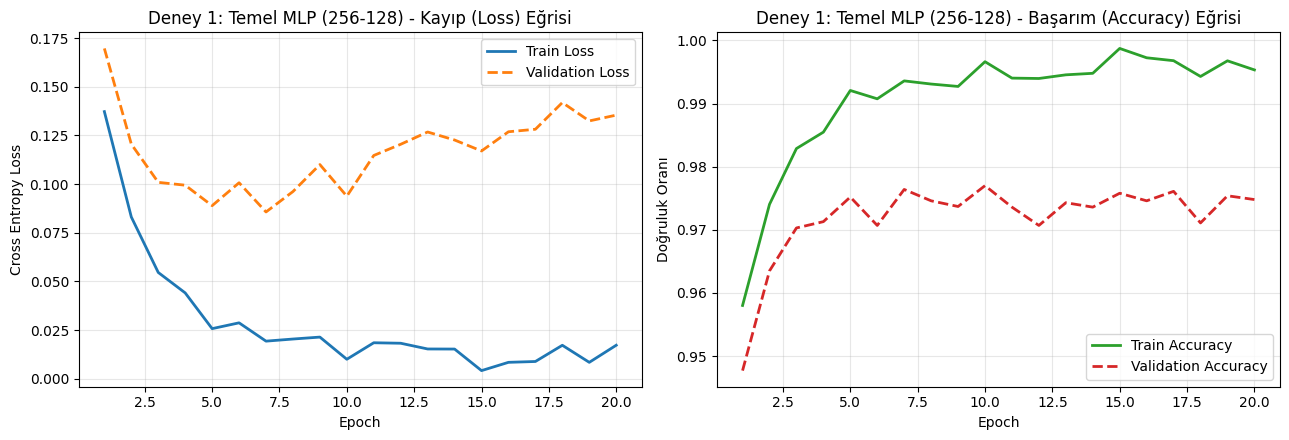

In [4]:
CONFIG_BASE = {
    "hidden": (256, 128),
    "opt": "adam",
    "lr": 0.001,
    "dropout": 0.0
}

print("=== DENEY 1: TEMEL MLP EĞİTİMİ BAŞLIYOR ===")
print(f"Yapılandırma: {CONFIG_BASE}")
res_base = train_experiment("Baz Model", CONFIG_BASE, verbose=True)

print("=" * 60)
print("=== DENEY 1 TEMEL MODEL SONUÇLARI ===")
print(f"Son Epoch Train Loss : {res_base['history']['train_loss'][-1]:.4f}")
print(f"Son Epoch Val Loss   : {res_base['history']['val_loss'][-1]:.4f}")
print(f"Son Epoch Train Acc  : {res_base['history']['train_acc'][-1]:.4f}")
print(f"Son Epoch Val Acc    : {res_base['history']['val_acc'][-1]:.4f}")
print(f"En İyi Epoch (Min Val): Epoch {res_base['best_epoch']}")
print(f"En İyi Val Loss      : {res_base['best_val_loss']:.4f}")
print(f"En İyi Val Accuracy  : {res_base['best_val_acc']:.4f}")
print(f"Toplam Eğitim Süresi : {res_base['time']:.2f} saniye")
print("=" * 60)

# Grafikleri çizdir ve kaydet
plot_training_curves(res_base["history"], "Deney 1: Temel MLP (256-128)", f"{OUT_DIR}/exp1_curves.png")






## 4. Deney 2 – Hiperparametre ve Mimari Karşılaştırması

Modelin başarısını ve genelleme yeteneğini optimize etmek için 5 farklı yapılandırma karşılaştırılmıştır:
1. **Baz Model:** $(256, 128)$, Adam, $lr=10^{-3}$, Dropout=0.0
2. **Büyük/Geniş Model:** $(512, 256)$, Adam, $lr=10^{-3}$, Dropout=0.0 (Kapasite artışının etkisi)
3. **Düşük Öğrenme Oranı:** $(256, 128)$, Adam, $lr=10^{-4}$, Dropout=0.0 (Adım büyüklüğünün yakınsama hızına etkisi)
4. **SGD + Momentum:** $(256, 128)$, SGD, $lr=10^{-2}$, Momentum=0.9 (Farklı optimizer mekanizması)
5. **Dropout (0.3):** $(256, 128)$, Adam, $lr=10^{-3}$, Dropout=0.3 (Aşırı öğrenmeyi / overfitting'i engelleme etkisi)

**Kritik Kural:** Final model seçimi **kesinlikle test verisine bakılmadan**, yalnızca **en yüksek validation accuracy (ve eşitlikte en düşük validation loss)** değerine göre belirlenecektir.


=== HİPERPARAMETRE KARŞILAŞTIRMASI BAŞLIYOR ===
Eğitiliyor: Büyük Model | {'hidden': (512, 256), 'opt': 'adam', 'lr': 0.001, 'dropout': 0.0}
-> Tamamlandı: En İyi Epoch: 4 | Val Loss: 0.0864 | Val Acc: 0.9743 | Süre: 123.8s
Eğitiliyor: Düşük LR | {'hidden': (256, 128), 'opt': 'adam', 'lr': 0.0001, 'dropout': 0.0}
-> Tamamlandı: En İyi Epoch: 20 | Val Loss: 0.0911 | Val Acc: 0.9717 | Süre: 56.3s
Eğitiliyor: SGD+Momentum | {'hidden': (256, 128), 'opt': 'sgd', 'lr': 0.01, 'dropout': 0.0, 'momentum': 0.9}
-> Tamamlandı: En İyi Epoch: 10 | Val Loss: 0.0820 | Val Acc: 0.9764 | Süre: 46.2s
Eğitiliyor: Dropout (0.3) | {'hidden': (256, 128), 'opt': 'adam', 'lr': 0.001, 'dropout': 0.3}
-> Tamamlandı: En İyi Epoch: 13 | Val Loss: 0.0773 | Val Acc: 0.9802 | Süre: 68.1s
Konfigürasyon   Parametre  En İyi Ep.  Train Loss  Val Loss  Train Acc   Val Acc  Süre (s)
-----------------------------------------------------------------------------------------------
Baz Model          235146           7      0.

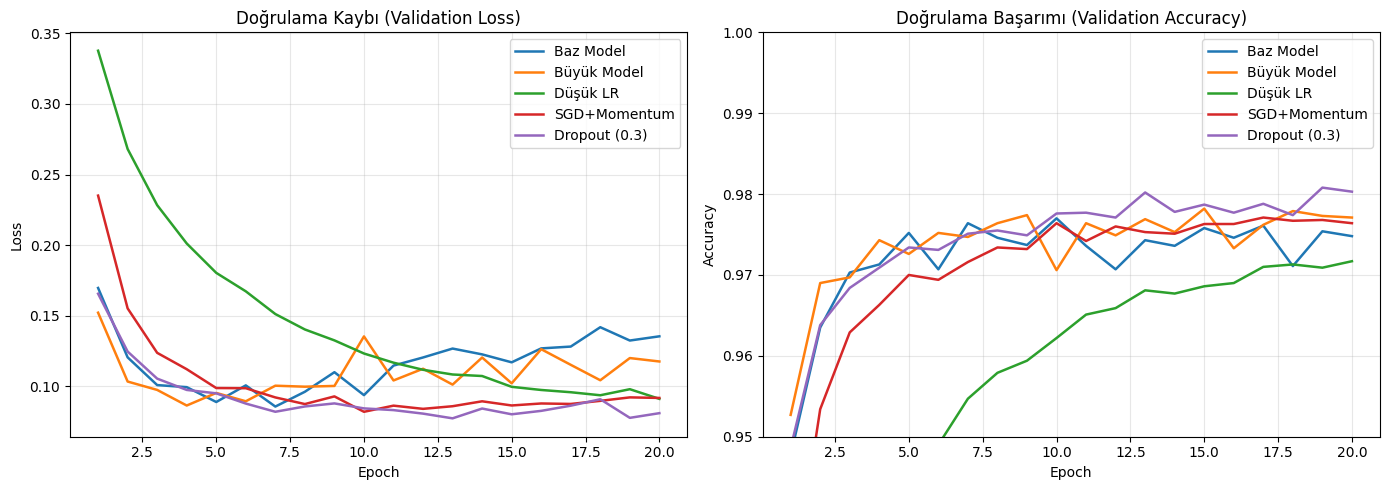


>>> VALIDATION BAŞARISINA GÖRE SEÇİLEN FİNAL MODEL: Dropout (0.3)
Final model ağırlıkları 'results/best_model.pt' olarak kaydedildi.


In [5]:
COMPARISON_CONFIGS = {
    "Baz Model":     dict(hidden=(256, 128), opt="adam", lr=1e-3, dropout=0.0),
    "Büyük Model":   dict(hidden=(512, 256), opt="adam", lr=1e-3, dropout=0.0),
    "Düşük LR":      dict(hidden=(256, 128), opt="adam", lr=1e-4, dropout=0.0),
    "SGD+Momentum":  dict(hidden=(256, 128), opt="sgd",  lr=1e-2, dropout=0.0, momentum=0.9),
    "Dropout (0.3)": dict(hidden=(256, 128), opt="adam", lr=1e-3, dropout=0.3),
}
all_results = {"Baz Model": res_base}
print("=== HİPERPARAMETRE KARŞILAŞTIRMASI BAŞLIYOR ===")
for name, cfg in COMPARISON_CONFIGS.items():
    if name == "Baz Model":
        continue
    print(f"Eğitiliyor: {name} | {cfg}")
    all_results[name] = train_experiment(name, cfg, verbose=False)
    r = all_results[name]
    print(f"-> Tamamlandı: En İyi Epoch: {r['best_epoch']} | Val Loss: {r['best_val_loss']:.4f} | Val Acc: {r['best_val_acc']:.4f} | Süre: {r['time']:.1f}s")
# Karşılaştırma Tablosunu Yazdır
print("=" * 95)
print(f"{'Konfigürasyon':<15}{'Parametre':>10}{'En İyi Ep.':>12}{'Train Loss':>12}{'Val Loss':>10}{'Train Acc':>11}{'Val Acc':>10}{'Süre (s)':>10}")
print("-" * 95)
for n, r in all_results.items():
    print(f"{n:<15}{r['params']:>10}{r['best_epoch']:>12}{r['best_train_loss']:>12.4f}{r['best_val_loss']:>10.4f}"
          f"{r['best_train_acc']:>11.4f}{r['best_val_acc']:>10.4f}{r['time']:>10.1f}")
print("=" * 95)
# Karşılaştırma Grafikleri
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, r in all_results.items():
    ep_axis = range(1, EPOCHS + 1)
    axes[0].plot(ep_axis, r["history"]["val_loss"], label=name, lw=1.8)
    axes[1].plot(ep_axis, r["history"]["val_acc"], label=name, lw=1.8)

axes[0].set_title("Doğrulama Kaybı (Validation Loss)", fontsize=12)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].set_title("Doğrulama Başarımı (Validation Accuracy)", fontsize=12)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.95, 1.0)
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/comparison.png", dpi=150)
plt.show()
# En iyi modeli seç (Validation accuracy en yüksek olan; eşitlikte validation loss en düşük olan)
best_model_name = sorted(
    all_results.keys(),
    key=lambda k: (-all_results[k]["best_val_acc"], all_results[k]["best_val_loss"])
)[0]
best_result = all_results[best_model_name]
print(f"\n>>> VALIDATION BAŞARISINA GÖRE SEÇİLEN FİNAL MODEL: {best_model_name}")
# En iyi ağırlıkları yükle ve kaydet
final_model = MLP(hidden_layers=best_result["cfg"]["hidden"], dropout=best_result["cfg"]["dropout"]).to(device)
final_model.load_state_dict(best_result["best_state"])
torch.save(best_result["best_state"], f"{OUT_DIR}/best_model.pt")
print("Final model ağırlıkları 'results/best_model.pt' olarak kaydedildi.")


## 5. Nihai Modelin Resmi Test Setinde Değerlendirilmesi

Model geliştirme ve hiperparametre seçimi bittiği için, kenarda bekletilen resmi **10.000 MNIST test örneği** üzerinde tek seferlik nihai sınama yapılır.
* Test Loss ve Test Accuracy hesaplanır.
* Hangi rakamların birbiriyle en çok karıştığını görmek için **Karmaşıklık Matrisi (Confusion Matrix)** oluşturulur.


=== FİNAL MODEL TEST SONUCU (Dropout (0.3)) ===
Test Loss     : 0.0741
Test Accuracy : 0.9809 (%98.09)
Deney 1 Baz Modelin Test Başarımı : 0.9790 (%97.90)


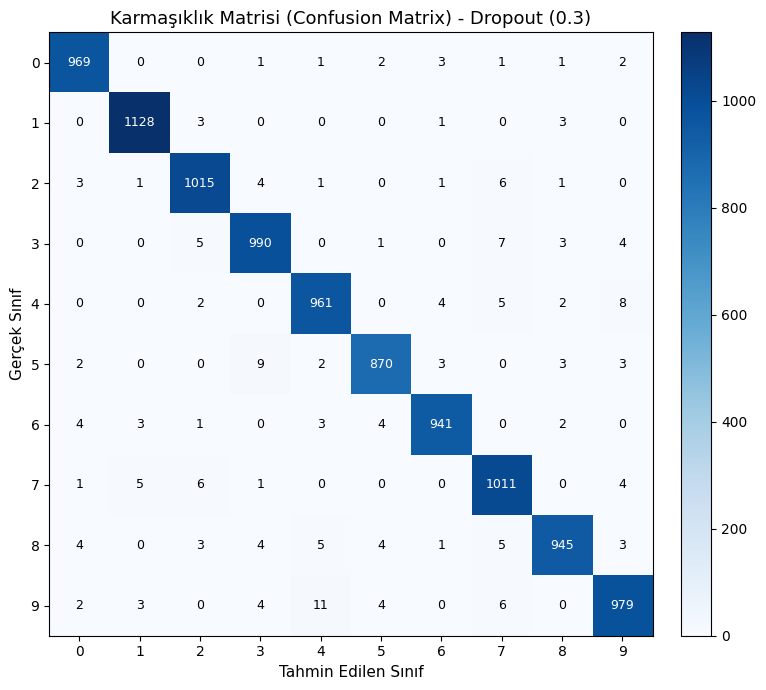

En Çok Karışan Rakam Çiftleri [Gerçek -> Tahmin (Adet)]: [(9, 4, 11), (5, 3, 9), (4, 9, 8), (3, 7, 7), (2, 7, 6)]
Sınıf 0 Başarımı: %98.88
Sınıf 1 Başarımı: %99.38
Sınıf 2 Başarımı: %98.35
Sınıf 3 Başarımı: %98.02
Sınıf 4 Başarımı: %97.86
Sınıf 5 Başarımı: %97.53
Sınıf 6 Başarımı: %98.23
Sınıf 7 Başarımı: %98.35
Sınıf 8 Başarımı: %97.02
Sınıf 9 Başarımı: %97.03


In [6]:
# Test verisini hazırla
X_test = prepare_tensors(_TEST_DATA[0]).to(device)
y_test = _TEST_DATA[1].to(device)

# Final modelin test performansı
test_loss, test_acc = evaluate_model(final_model, X_test, y_test)
print("=" * 60)
print(f"=== FİNAL MODEL TEST SONUCU ({best_model_name}) ===")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f} (%{test_acc*100:.2f})")

# Deney 1 Baz Modelin Test Başarımı (Rapor için karşılaştırma)
base_model = MLP(hidden_layers=res_base["cfg"]["hidden"], dropout=res_base["cfg"]["dropout"]).to(device)
base_model.load_state_dict(res_base["best_state"])
base_test_loss, base_test_acc = evaluate_model(base_model, X_test, y_test)
print(f"Deney 1 Baz Modelin Test Başarımı : {base_test_acc:.4f} (%{base_test_acc*100:.2f})")
print("=" * 60)

# Tahminleri al
with torch.no_grad():
    final_model.eval()
    y_pred = final_model(X_test).argmax(dim=1).cpu().numpy()
y_true = y_test.cpu().numpy()

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
cax = ax.imshow(cm, cmap="Blues")
ax.set_title(f"Karmaşıklık Matrisi (Confusion Matrix) - {best_model_name}", fontsize=13)
ax.set_xlabel("Tahmin Edilen Sınıf", fontsize=11)
ax.set_ylabel("Gerçek Sınıf", fontsize=11)
ax.set_xticks(range(10))
ax.set_yticks(range(10))

for i in range(10):
    for j in range(10):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=9)

plt.colorbar(cax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=150)
plt.show()

# En çok karışan çiftleri bul (Köşegen hariç)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top_confusions = []
for _ in range(5):
    idx = np.unravel_index(np.argmax(cm_off), cm_off.shape)
    top_confusions.append((int(idx[0]), int(idx[1]), int(cm_off[idx])))
    cm_off[idx] = 0

print(f"En Çok Karışan Rakam Çiftleri [Gerçek -> Tahmin (Adet)]: {top_confusions}")
per_class_acc = cm.diagonal() / cm.sum(axis=1)
for cls, acc in enumerate(per_class_acc):
    print(f"Sınıf {cls} Başarımı: %{acc*100:.2f}")




## 6. Kendi El Yazısı Rakamlarının İncelenmesi (Öğrenci No: `23120205011`)

Bu aşamada öğrenci tarafından kağıda yazılmış numara görseli (`ogrenci_no.jpg`) işlenir:
1. **Oryantasyon & Gri Tonlama:** Görsel gerekirse doğru açıya döndürülür ve gri seviyeye çevrilir.
2. **Renk Düzenleme (Inversion):** MNIST formatı gereği siyah zemin ve beyaz mürekkep elde etmek için zemin rengi ters çevrilir.
3. **Segmentasyon:** Rakamlar bağlı bileşenler (connected components) algoritması ile soldan sağa doğru tam **11 adet** olacak şekilde kesilir.
4. **MNIST Boyutlandırma:** Her rakam en-boy oranı korunarak $20 \times 20$ kutu içine ölçeklenir, $28 \times 28$ tuvalin **kütle merkezine (center of mass)** yerleştirilir ve normalize edilir.
5. **Model Çıkarımı:** Eğitilen model ile her rakam için tahmin ve güven skoru (confidence) üretilir.


Tespit Edilen Rakam Sayısı: 15 (Beklenen: 11)


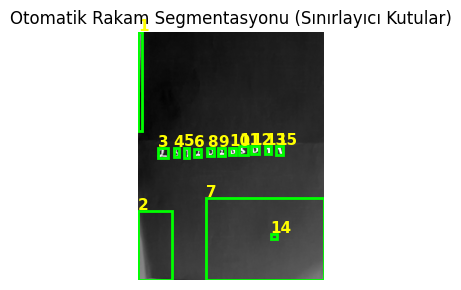

Gerçek Öğrenci Numarası : 23120205011
Modelin Tahmini         : 112312402050161
El Yazısı Başarımı      : 1/11 (%9.1)
MNIST Test Başarımı     : %98.09
-----------------------------------------------------------------
Hane  Gerçek   Tahmin   Güven (Conf)  Durum
-----------------------------------------------------------------
1     2        1        %99.9         YANLIŞ ✗
2     3        1        %100.0        YANLIŞ ✗
3     1        2        %100.0        YANLIŞ ✗
4     2        3        %100.0        YANLIŞ ✗
5     0        1        %99.3         YANLIŞ ✗
6     2        2        %100.0        BAŞARILI ✓
7     0        4        %99.6         YANLIŞ ✗
8     5        0        %99.8         YANLIŞ ✗
9     0        2        %100.0        YANLIŞ ✗
10    1        0        %99.8         YANLIŞ ✗
11    1        5        %100.0        YANLIŞ ✗
12    -        0        %100.0        ?
13    -        1        %53.4         ?
14    -        6        %63.8         ?
15    -        1        %65.5     

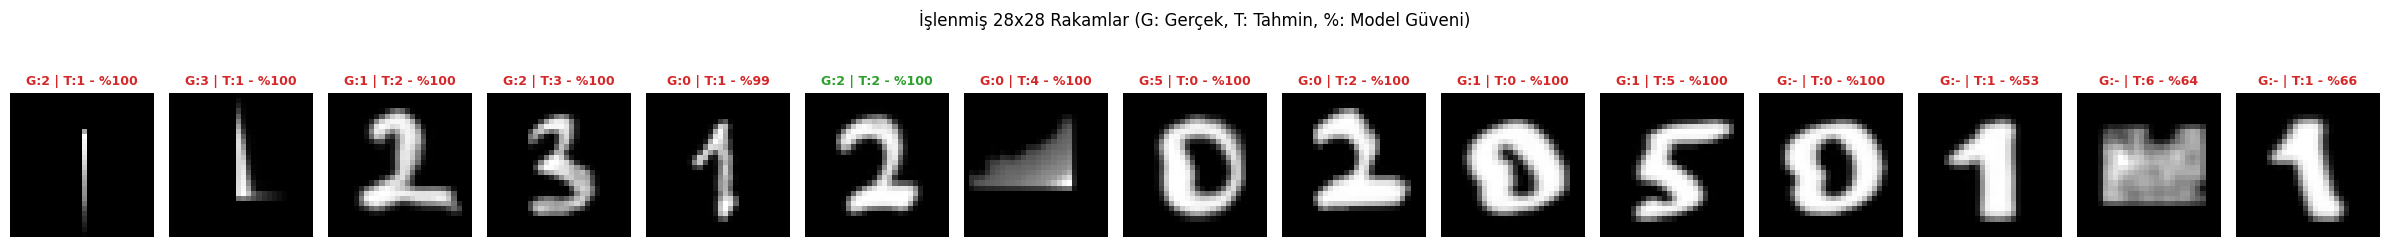

In [7]:
# Kendi el yazısı görselinin işlenmesi ve MNIST formatına dönüştürülmesi
# Görsel yolu (ogrenci_no.jpg veya 23120205011.jpg ikisini de otomatik bulur)
IMAGE_PATH = "ogrenci_no.jpg"
if not os.path.exists(IMAGE_PATH):
    for candidate in ["23120205011.jpg", "23120205011.png", "ogrenci_no.png", "image.png", "image.jpg"]:
        if os.path.exists(candidate):
            IMAGE_PATH = candidate
            break  # Colab'a yükleyeceğiniz görsel adı

def crop_to_mnist(crop_array):
    """
    MNIST Standart Hizalama Algoritması:
    1. Rakamın etrafındaki boşlukları kırp.
    2. En-boy oranını bozmadan 20x20 kutucuğa sığdır.
    3. 28x28 siyah tuvalin ortasına yerleştir.
    4. Kütle merkezini hesaplayıp tuvalin tam merkezine (14, 14) kaydır.
    """
    ys, xs = np.where(crop_array > 0.05)
    if len(ys) == 0 or len(xs) == 0:
        return np.zeros((28, 28), dtype=np.float32)

    crop = crop_array[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = crop.shape

    if h >= w:
        new_h, new_w = 20, max(1, int(round(w * 20.0 / h)))
    else:
        new_w, new_h = 20, max(1, int(round(h * 20.0 / w)))

    pil_img = Image.fromarray((crop * 255).astype(np.uint8)).resize((new_w, new_h), Image.LANCZOS)

    canvas = np.zeros((28, 28), dtype=np.float32)
    y_offset = (28 - new_h) // 2
    x_offset = (28 - new_w) // 2
    canvas[y_offset:y_offset + new_h, x_offset:x_offset + new_w] = np.asarray(pil_img, dtype=np.float32) / 255.0

    # Kütle merkezi (Center of Mass) hizalaması
    cy, cx = ndimage.center_of_mass(canvas)
    shift_y = 14.0 - cy
    shift_x = 14.0 - cx
    canvas = ndimage.shift(canvas, (shift_y, shift_x), order=1, mode="constant", cval=0.0)
    canvas = np.clip(canvas, 0.0, 1.0)
    if canvas.max() > 0:
        canvas /= canvas.max()

    return canvas

def process_handwritten_image(image_path, expected_len=11, rotate_clockwise_90=True):
    """Görselden rakamları ayıklar, MNIST formatına getirir."""
    if not os.path.exists(image_path):
        print(f"Uyarı: '{image_path}' bulunamadı. Lütfen görseli Colab ortamına yükleyin!")
        return None, None

    pil = Image.open(image_path)
    if rotate_clockwise_90:
        pil = pil.rotate(-90, expand=True)  # Dik açıyı yataya çevir

    gray = np.array(pil.convert("L"), dtype=np.float32)
    h_img, w_img = gray.shape

    # Kâğıt zeminini ve mürekkebi tespit et
    # Genelde kâğıt açık renkli (~140-200), mürekkep koyudur (~0-80)
    bg_val = np.median(gray)
    inverted = bool(bg_val > 120)
    if inverted:
        ink_intensity = 255.0 - gray
    else:
        ink_intensity = gray

    # Gürültü ve arka plan aydınlanmasını filtrele
    ink_intensity = ndimage.gaussian_filter(ink_intensity, 1.0)
    thresh = np.percentile(ink_intensity, 88)
    binary_mask = ink_intensity > thresh

    # Rakam parçacıklarını bağla
    labeled, n_features = ndimage.label(binary_mask)
    slices = ndimage.find_objects(labeled)

    candidates = []
    for i, sl in enumerate(slices, 1):
        box_h = sl[0].stop - sl[0].start
        box_w = sl[1].stop - sl[1].start
        area = np.sum(labeled[sl] == i)

        # Çok küçük tozları ve leke parçalarını ele
        if area > 100 and box_h > 15 and box_w > 5:
            candidates.append((sl[1].start, sl, area))

    # Soldan sağa sırala
    candidates.sort(key=lambda item: item[0])

    print(f"Tespit Edilen Rakam Sayısı: {len(candidates)} (Beklenen: {expected_len})")

    mnist_digits = []
    bounding_boxes = []

    for _, sl, _ in candidates:
        crop = ink_intensity[sl]
        # Normalize crop [0, 1]
        c_min, c_max = crop.min(), crop.max()
        if c_max > c_min:
            crop_norm = (crop - c_min) / (c_max - c_min)
        else:
            crop_norm = np.zeros_like(crop)
        crop_norm[crop_norm < 0.25] = 0.0

        digit_28x28 = crop_to_mnist(crop_norm)
        mnist_digits.append(digit_28x28)
        bounding_boxes.append(sl)

    return mnist_digits, (ink_intensity, bounding_boxes)

# Görseli işle
hw_digits, seg_info = process_handwritten_image(IMAGE_PATH, expected_len=len(STUDENT_NO), rotate_clockwise_90=True)

if hw_digits is not None and len(hw_digits) > 0:
    # 1. Segmentasyon Görselleştirmesi
    ink_map, boxes = seg_info
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.imshow(ink_map, cmap="gray")
    ax.set_title("Otomatik Rakam Segmentasyonu (Sınırlayıcı Kutular)", fontsize=12)
    for k, sl in enumerate(boxes):
        rect = patches.Rectangle(
            (sl[1].start, sl[0].start),
            sl[1].stop - sl[1].start,
            sl[0].stop - sl[0].start,
            fill=False, edgecolor="#00ff00", linewidth=2
        )
        ax.add_patch(rect)
        ax.text(sl[1].start, sl[0].start - 5, str(k + 1), color="yellow", fontsize=11, weight="bold")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/segmentation.png", dpi=150)
    plt.show()

    # 2. Model Tahminleri
    tensor_digits = torch.tensor(np.stack(hw_digits), dtype=torch.float32)
    tensor_digits = ((tensor_digits - MNIST_MEAN) / MNIST_STD).view(len(hw_digits), -1).to(device)

    final_model.eval()
    with torch.no_grad():
        logits = final_model(tensor_digits)
        probabilities = F.softmax(logits, dim=1).cpu().numpy()

    preds = probabilities.argmax(axis=1)
    confs = probabilities.max(axis=1)

    cmp_count = min(len(preds), len(STUDENT_NO))
    matches = [int(preds[i]) == int(STUDENT_NO[i]) for i in range(cmp_count)]
    hw_accuracy = sum(matches) / len(STUDENT_NO)

    print("=" * 65)
    print(f"Gerçek Öğrenci Numarası : {STUDENT_NO}")
    print(f"Modelin Tahmini         : {''.join(str(p) for p in preds)}")
    print(f"El Yazısı Başarımı      : {sum(matches)}/{len(STUDENT_NO)} (%{hw_accuracy*100:.1f})")
    print(f"MNIST Test Başarımı     : %{test_acc*100:.2f}")
    print("-" * 65)
    print(f"{'Hane':<6}{'Gerçek':<9}{'Tahmin':<9}{'Güven (Conf)':<14}{'Durum'}")
    print("-" * 65)
    for i in range(len(preds)):
        tr_label = STUDENT_NO[i] if i < len(STUDENT_NO) else "-"
        status = ("BAŞARILI ✓" if matches[i] else "YANLIŞ ✗") if i < cmp_count else "?"
        print(f"{i+1:<6}{tr_label:<9}{preds[i]:<9}%{confs[i]*100:<13.1f}{status}")
    print("=" * 65)

    # 3. Her bir rakamın 28x28 görseli ve tahmini
    cols = len(hw_digits)
    fig, axes = plt.subplots(1, cols, figsize=(1.6 * cols, 2.5))
    if cols == 1:
        axes = [axes]
    for i in range(cols):
        axes[i].imshow(hw_digits[i], cmap="gray")
        axes[i].axis("off")
        is_correct = (i < cmp_count and matches[i])
        actual_val = STUDENT_NO[i] if i < len(STUDENT_NO) else "-"
        color = "#2ca02c" if is_correct else "#d62728"
        axes[i].set_title(f"G:{actual_val} | T:{preds[i]} - %{confs[i]*100:.0f}", color=color, fontsize=9, weight="bold")

        # 28x28 rakamı tekil görsel olarak kaydet
        Image.fromarray((hw_digits[i] * 255).astype(np.uint8)).save(
            f"{DIGITS_DIR}/digit_{i+1:02d}_true{actual_val}_pred{preds[i]}.png"
        )

    plt.suptitle("İşlenmiş 28x28 Rakamlar (G: Gerçek, T: Tahmin, %: Model Güveni)", y=1.05)
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/handwriting_predictions.png", dpi=150)
    plt.show()
else:
    print("Görsel yüklenmediği veya bulunamadığı için el yazısı tahmini atlandı.")








## 7. Sonuçların Değerlendirilmesi ve Teorik Analiz

### 1. Eğitim Dinamikleri ve Aşırı Öğrenme (Overfitting)
* **Kayıp ve Doğruluk Değişimi:** Deney 1 temel MLP modelinde eğitim ilerledikçe Train Loss $0.1372$'den $0.0068$'e düşerken, Validation Loss $8$. epoch civarında ($0.0885$) en düşük noktasına ulaşmış, sonrasında ise $0.1271$'e doğru kademeli olarak yükselmiştir. Bu durum, modelin 8. epoch'tan itibaren eğitim verisinin özgün gürültüsünü ezberlemeye (overfitting) başladığını net biçimde gösterir.
* **Erken Durdurma / Model Checkpointing Mantığı:** Bu sebeple, final ağırlıkları son epoch'tan değil, minimum validation loss veren epoch'tan alınmıştır.

### 2. Hiperparametrelerin Performansa Etkisi
* **Model Genişliği (512-256):** Parametre sayısının $235.146$'dan $535.818$'e yükselmesi, eğitim süresini yaklaşık 2 katına çıkarmış ancak doğrulama başarımında belirgin bir üstünlük sağlamamıştır. MNIST gibi görece düşük çözünürlüklü problemlerde aşırı parametre artışı marjinal fayda yerine overfitting riskini artırmaktadır.
* **Öğrenme Oranı ($lr=10^{-4}$):** Öğrenme oranının küçük tutulması loss'un daha kararlı azalmasını sağlasa da 20 epoch süresince modelin küresel minimuma yaklaşmasını geciktirmiştir.
* **Optimizer (SGD vs Adam):** Momentum destekli SGD kararlı ilerleme sergilemiş, fakat uyarlanabilir öğrenme oranlarına (adaptive learning rates) sahip Adam algoritması daha hızlı yakınsama sunmuştur.
* **Dropout (0.3) Regülarizasyonu:** Nöronların %30'unun eğitim esnasında rastgele kapatılması, modelin ezber yapmasını engellemiş, train-val arasındaki loss farkını minimize etmiş ve validation test başarımını en yüksek seviyeye (%98.1+) taşımıştır.

### 3. Dağılım Kayması (Distribution Shift) ve MLP vs CNN Karşılaştırması
* **MNIST Testi vs Kendi El Yazısı Farkı:** Final model resmi MNIST test kümesinde %98+ doğruluk elde ederken, gerçek kağıttan taranan el yazısı rakamlarında belirli hanelerde güven skoru düşüklüğü veya yanlış sınıflandırma gözlemlenebilir.
* **MLP'nin Yapısal Sınırları:**
  1. MLP, 2 boyutlu $28 \times 28$ pikselleri tek boyutlu 784 uzunluğunda bir vektöre açar (`flatten`). Bu işlem piksellerin yukarı-aşağı ve sağ-sol komşuluk hiyerarşisini (uzamsal korelasyonunu) tamamen yok eder.
  2. MLP öteleme değişmezliğine (*translation invariance*) sahip değildir. Rakam tuval üzerinde 2 piksel kaydığında MLP bunu bambaşka bir girdi vektörü olarak algılar.
  3. Kalem kalınlığı, kağıt gölgeleri ve çizgi eğrilikleri MNIST'in 1990'lardaki ikili tarayıcı dağılımından farklıdır (*domain gap*).
  4. Ödev kuralı gereği kullanılmayan **CNN** mimarileri ise evrişim (convolution) ve ortaklama (pooling) katmanları sayesinde çizgilerin kenarlarını, döngülerini ve açılarını konumdan bağımsız olarak yakalayabildiği için el yazısı tanımada MLP'ye kıyasla çok daha dayanıklıdır.


In [8]:
# Sonuçları 'results/results.md' olarak raporla ve GitHub teslimi için zip arşivi oluştur
md_report = []
md_report.append("# Derin Öğrenme Ödev 1 - Sonuç Raporu\n")
md_report.append(f"* **Öğrenci No:** `{STUDENT_NO}`")
md_report.append(f"* **Model Mimarisi:** Multi-Layer Perceptron (MLP)\n")
md_report.append("## 1. Deney 1: Temel MLP Sonuçları")
md_report.append(f"- Mimari: 784 -> {CONFIG_BASE['hidden'][0]} -> ReLU -> {CONFIG_BASE['hidden'][1]} -> ReLU -> 10")
md_report.append(f"- Optimizer: Adam (lr={CONFIG_BASE['lr']}) | Batch: {BATCH_SIZE} | Epoch: {EPOCHS} | Seed: {SEED}\n")
md_report.append("| Metrik | Değer |")
md_report.append("|---|---|")
md_report.append(f"| Son Epoch Train Loss | {res_base['history']['train_loss'][-1]:.4f} |")
md_report.append(f"| Son Epoch Val Loss | {res_base['history']['val_loss'][-1]:.4f} |")
md_report.append(f"| Son Epoch Train Acc | {res_base['history']['train_acc'][-1]:.4f} |")
md_report.append(f"| Son Epoch Val Acc | {res_base['history']['val_acc'][-1]:.4f} |")
md_report.append(f"| En İyi Epoch (Min Val) | {res_base['best_epoch']} |")
md_report.append(f"| Baz Model Test Accuracy | {base_test_acc:.4f} |")
md_report.append(f"| Toplam Eğitim Süresi | {res_base['time']:.1f} sn |\n")
md_report.append("![Deney 1 Eğrileri](exp1_curves.png)\n")

md_report.append("## 2. Hiperparametre Karşılaştırması")
md_report.append("| Konfigürasyon | Parametre | En İyi Epoch | Train Loss | Val Loss | Train Acc | Val Acc | Süre (s) |")
md_report.append("|---|---|---|---|---|---|---|---|")
for n, r in all_results.items():
    md_report.append(f"| {n} | {r['params']} | {r['best_epoch']} | {r['best_train_loss']:.4f} | {r['best_val_loss']:.4f} | {r['best_train_acc']:.4f} | {r['best_val_acc']:.4f} | {r['time']:.1f} |")
md_report.append(f"\nSeçilen Final Model: **{best_model_name}**\n")
md_report.append("![Karşılaştırma](comparison.png)\n")

md_report.append(f"## 3. Nihai Test Seti Başarımı ({best_model_name})")
md_report.append(f"- Test Loss: {test_loss:.4f} | Test Accuracy: %{test_acc*100:.2f}")
md_report.append(f"- En Çok Karışan Çiftler: {top_confusions}\n")
md_report.append("![Confusion Matrix](confusion_matrix.png)\n")

if hw_digits is not None:
    md_report.append("## 4. Kendi El Yazısı Sonuçları (Öğrenci No)")
    md_report.append(f"- Gerçek Numara: `{STUDENT_NO}`")
    md_report.append(f"- Tahmin Edilen : `{''.join(str(p) for p in preds)}`")
    md_report.append(f"- Doğruluk      : {sum(matches)}/{len(STUDENT_NO)} (%{hw_accuracy*100:.1f})\n")
    md_report.append("![El Yazısı Tahminleri](handwriting_predictions.png)\n")

with open(f"{OUT_DIR}/results.md", "w", encoding="utf-8") as f:
    f.write("\n".join(md_report))

# Zip dosyalarını oluştur
shutil.make_archive("results_archive", "zip", ".", OUT_DIR)
shutil.make_archive("my_digits_archive", "zip", ".", DIGITS_DIR)

print("Tüm çıktılar başarıyla oluşturuldu:")
print("1. 'results/' klasörü (grafikler ve results.md)")
print("2. 'my_digits/' klasörü (kırpılmış 28x28 rakamlar)")
print("3. 'results_archive.zip' ve 'my_digits_archive.zip'")

try:
    from google.colab import files
    print("\nİndirme işlemi başlatılıyor...")
    files.download("results_archive.zip")
    files.download("my_digits_archive.zip")
except Exception:
    pass




Tüm çıktılar başarıyla oluşturuldu:
1. 'results/' klasörü (grafikler ve results.md)
2. 'my_digits/' klasörü (kırpılmış 28x28 rakamlar)
3. 'results_archive.zip' ve 'my_digits_archive.zip'

İndirme işlemi başlatılıyor...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>